<a href="https://colab.research.google.com/github/denizsecmen/AOEII-AI-Prediction/blob/main/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
#Importing Libaries
import sys
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing  import StandardScaler

In [48]:
#Retrieve main data
data=pd.read_csv("/content/drive/MyDrive/AOEII-data/rankedrm.csv",encoding="latin-1")
data=pd.DataFrame(data)
data.dropna(subset=["started","finished","map_type","rating.win","civ.win","rating.lose","rating_change.lose","duration","country.lose"])
print(data.columns)

Index(['match_uuid', 'started', 'finished', 'map_type', 'steam_id.win',
       'name.win', 'country.win', 'rating.win', 'rating_change.win', 'civ.win',
       'color.win', 'steam_id.lose', 'name.lose', 'country.lose',
       'rating.lose', 'rating_change.lose', 'civ.lose', 'color.lose',
       'map_type.name', 'civ.lose.name', 'civ.win.name', 'matchup',
       'duration'],
      dtype='object')


In [49]:
#Displaying main info about data
played_maps = data.groupby("map_type").size().reset_index(name="played_games_count")
civ_winner = data.groupby("civ.win").size().reset_index(name="civilisation_name_count")
rating_diff= data[["rating.win","rating.lose"]].apply(lambda x:x["rating.win"]-x["rating.lose"],axis=1)
rating_diff=pd.DataFrame(rating_diff[np.isnan(rating_diff)==False],columns=["Difference"])
rating_diff = ((rating_diff["Difference"] // 100 * 100).value_counts().sort_index()).reset_index(name="difference_count")
print("Rating difference")
print(rating_diff)
print("\n")
print("Player maps per game")
print(played_maps)
print("\n")
print("Civilisation per game")
print(civ_winner)

Rating difference
    Difference  difference_count
0       -700.0                 1
1       -600.0                 1
2       -500.0                 3
3       -400.0                 9
4       -300.0                62
5       -200.0               524
6       -100.0             35178
7          0.0             56477
8        100.0              1310
9        200.0               181
10       300.0                62
11       400.0                30
12       500.0                19
13       600.0                10
14       700.0                 2
15      1000.0                 1


Player maps per game
    map_type  played_games_count
0          9               66158
1         16                3445
2         19                1990
3         21                 651
4         29               12144
5         33                2149
6         67                3354
7         71                1963
8         72                2211
9         77                1861
10       140                6487
11

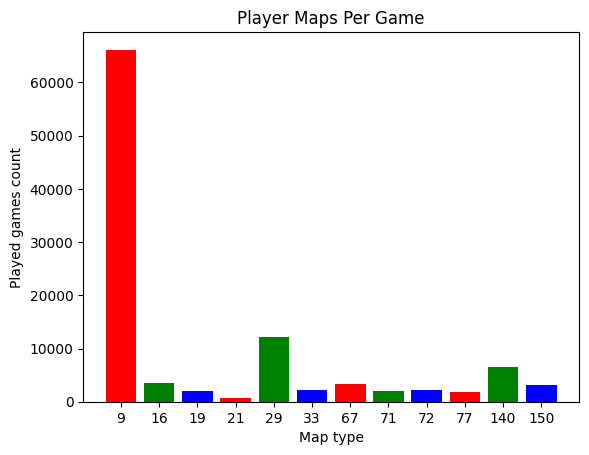

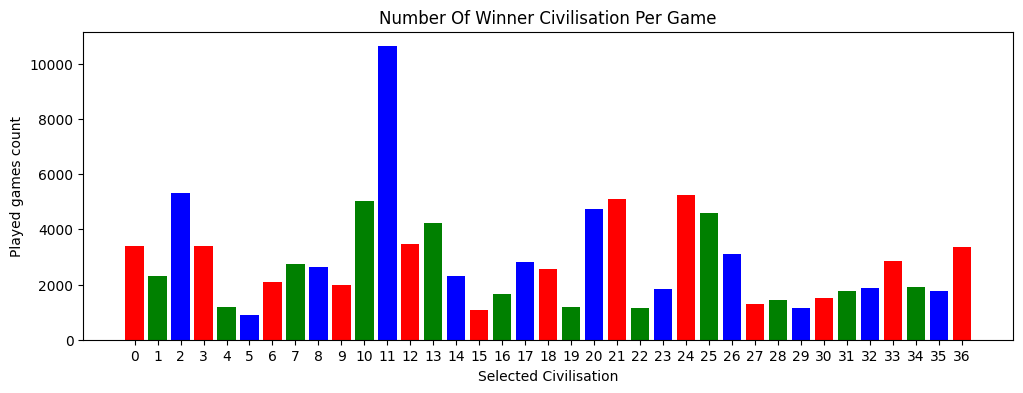

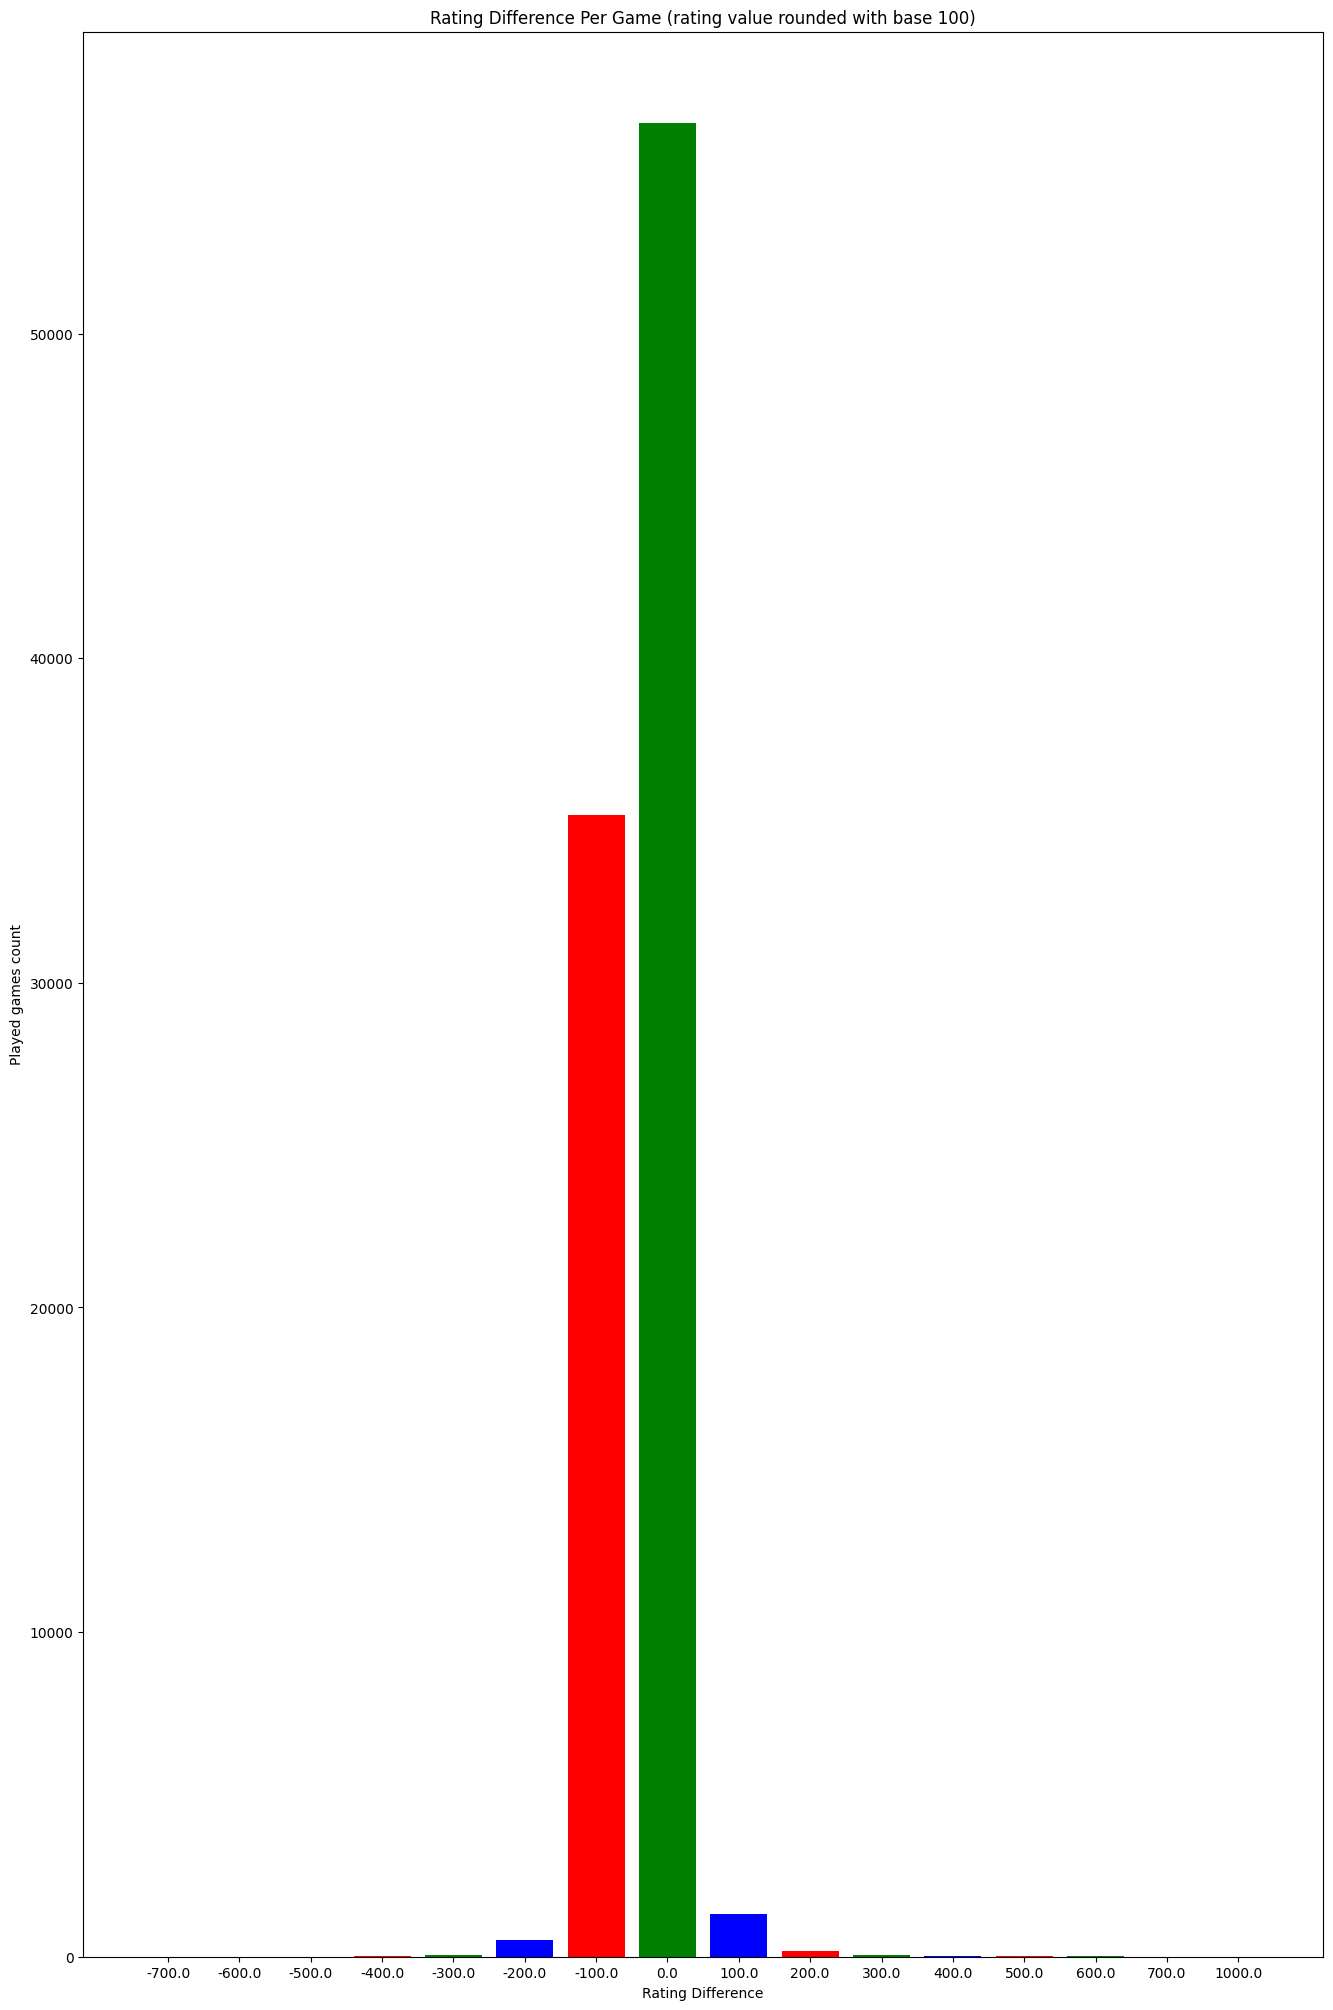

In [50]:
#Displaying main info about data with bar graph
plt.bar(x=played_maps["map_type"].astype(str),height=played_maps["played_games_count"],color=["red","green","blue",])
plt.title("Player Maps Per Game")
plt.xlabel("Map type")
plt.ylabel("Played games count")
plt.show()
plt.figure(figsize=(12,4))
plt.bar(x=civ_winner["civ.win"].astype(str),height=civ_winner["civilisation_name_count"],color=["red","green","blue",])
plt.title("Number Of Winner Civilisation Per Game")
plt.xlabel("Selected Civilisation")
plt.ylabel("Played games count")
plt.show()
plt.figure(figsize=(16,25))
plt.bar(x=rating_diff["Difference"].astype(str),height=rating_diff["difference_count"],color=["red","green","blue",])
plt.title("Rating Difference Per Game (rating value rounded with base 100)")
plt.xlabel("Rating Difference")
plt.ylabel("Played games count")
plt.show()

In [86]:
#Prerocessing
str_columns=[column for column in data.columns if data[column].dtype!=int and  data[column].dtype!=float]
print(str_columns)
data.drop([*str_columns],axis=1,inplace=True)
print(data.columns)
sc=StandardScaler()
sc.fit(data)
print(sc.transform(data))

[]
Index(['map_type', 'rating.win', 'rating_change.win', 'civ.win', 'color.win',
       'rating.lose', 'rating_change.lose', 'civ.lose', 'color.lose'],
      dtype='object')
[[-0.52522646 -0.05326642  0.14085959 ... -0.07694798 -0.46541259
   0.58464637]
 [-0.27655431  1.82623243         nan ...         nan  1.0849817
  -0.72341884]
 [-0.52522646  0.45123064  0.14085959 ... -0.07694798 -1.43440902
  -0.72341884]
 ...
 [-0.02788215 -0.60722397         nan ...         nan -0.65921188
  -0.06938623]
 [ 1.0165409  -1.02269213 -0.25475996 ...  0.27538283  0.4066842
  -0.06938623]
 [-0.52522646 -0.66987393 -0.25475996 ...  0.27538283 -0.46541259
  -0.06938623]]
